# Vegetation indices, harvest dates and seasons

Loads the Sentinel-2 series, computes vegetation indices, detects the harvest
date of each cycle, builds the season (safra) intervals and plots the series
with the harvests marked. Figures go to `figures/`, tables to `data/processed/`.

In [1]:
# ---- CONFIGURATION (edit here) ----
INDICES_TO_COMPUTE = ["NDVI", "EVI", "NDRE", "NDMI", "NDTI"]
INDICES_TO_PLOT = ["NDVI"]  # 1 or 2 indices
FIELDS_TO_PLOT = [1440, 1460]  # one figure per field
NDVI_THRESHOLD = 0.30  # NDVI at or below this means no live canopy
SHOW_HARVESTS = True  # mark harvest dates with a red asterisk
SAVE_FIGURES = True

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt

from cane_cycle.harvest import build_seasons, detect_harvests
from cane_cycle.io import load_s2_csv
from cane_cycle.plotting import plot_index_timeseries
from cane_cycle.vegetation_indices import add_indices

# Works whether this runs from the project root or from notebooks/.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = PROJECT_DIR / "data" / "raw" / "fields_example_s2.csv"
INDICES_FILE = PROJECT_DIR / "data" / "processed" / "s2_indices.csv"
HARVEST_FILE = PROJECT_DIR / "data" / "processed" / "harvest_dates.csv"
SEASONS_FILE = PROJECT_DIR / "data" / "processed" / "seasons.csv"
FIGURES_DIR = PROJECT_DIR / "figures"

In [3]:
df = load_s2_csv(RAW_FILE)
print(f"{len(df)} rows, fields: {sorted(df['field_id'].unique())}")
print(f"from {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
df.head()

964 rows, fields: [np.int64(1440), np.int64(1460)]
from 2019-01-10 to 2026-09-25


C:\Users\ju_fo\AppData\Local\Temp\ipykernel_11992\2064776681.py:1: UserWarning: Dropped 2 rows with unreadable band values on 1 dates: 2026-09-21
  df = load_s2_csv(RAW_FILE)


,fonte,date,field_id,granuleID,pixelTotal,B1,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,coverage_pct
0,S2,2019-01-10,1440,L2A_T22K,4599,0.060076,0.080203,0.106059,0.147571,0.184043,0.212009,0.239522,0.249682,0.273818,0.417225,0.328715,100.0
1,S2,2019-01-15,1440,L2A_T22K,4599,0.569196,0.488870,0.464344,0.434051,0.493739,0.540574,0.558158,0.547149,0.566092,0.375156,0.358218,100.0
2,S2,2019-01-20,1440,L2A_T22K,4599,0.058165,0.080585,0.108030,0.156243,0.189861,0.207924,0.235563,0.242608,0.272648,0.438454,0.341696,100.0
3,S2,2019-01-25,1440,L2A_T22K,4599,0.064211,0.079458,0.108143,0.158343,0.191853,0.213444,0.234308,0.242552,0.273854,0.441287,0.334082,100.0
4,S2,2019-01-30,1440,L2A_T22K,4599,0.062121,0.084823,0.111290,0.161248,0.193650,0.210129,0.236431,0.244934,0.271180,0.439404,0.344913,100.0


In [4]:
df = add_indices(df, indices=INDICES_TO_COMPUTE)

INDICES_FILE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(INDICES_FILE, index=False)

df[INDICES_TO_COMPUTE].describe().round(3)

,NDVI,EVI,NDRE,NDMI,NDTI
count,964.000,964.000,964.000,964.000,964.000
mean,0.384,0.223,0.281,0.073,0.161
std,0.219,2.337,0.175,0.164,0.089
min,-0.106,-53.372,-0.089,-0.291,-0.083
25%,0.195,0.166,0.137,-0.076,0.095
50%,0.364,0.293,0.261,0.080,0.149
75%,0.576,0.446,0.424,0.203,0.238
max,0.807,5.453,0.653,0.593,0.348


In [5]:
harvests = detect_harvests(df, ndvi_max=NDVI_THRESHOLD)
harvests.to_csv(HARVEST_FILE, index=False)
harvests

,field_id,season,harvest_date,ndvi_at_harvest,cycle_peak_ndvi
0,1440,2020/21,2020-05-19,0.237544,0.768429
1,1440,2021/22,2021-09-01,0.211026,0.777985
2,1440,2023/24,2023-09-01,0.171239,0.739919
3,1440,2025/26,2025-06-17,0.236859,0.794166
4,1460,2019/20,2019-09-07,0.174736,0.641111
5,1460,2020/21,2020-08-12,0.208004,0.806682
6,1460,2021/22,2021-09-06,0.278594,0.545782
7,1460,2022/23,2022-08-12,0.257723,0.793516
8,1460,2023/24,2023-09-06,0.186934,0.748450
9,1460,2024/25,2024-07-07,0.281252,0.560592


In [6]:
seasons = build_seasons(df, harvests)
seasons.to_csv(SEASONS_FILE, index=False)
seasons

,field_id,season,start_date,end_date,duration_days,open_season
0,1440,2020/21,2019-01-10,2020-05-19,495,True
1,1440,2021/22,2020-05-19,2021-09-01,470,False
2,1440,2023/24,2021-09-01,2023-09-01,730,False
3,1440,2025/26,2023-09-01,2025-06-17,655,False
4,1440,2026/27,2025-06-17,2026-09-25,465,True
5,1460,2019/20,2019-01-10,2019-09-07,240,True
6,1460,2020/21,2019-09-07,2020-08-12,340,False
7,1460,2021/22,2020-08-12,2021-09-06,390,False
8,1460,2022/23,2021-09-06,2022-08-12,340,False
9,1460,2023/24,2022-08-12,2023-09-06,390,False


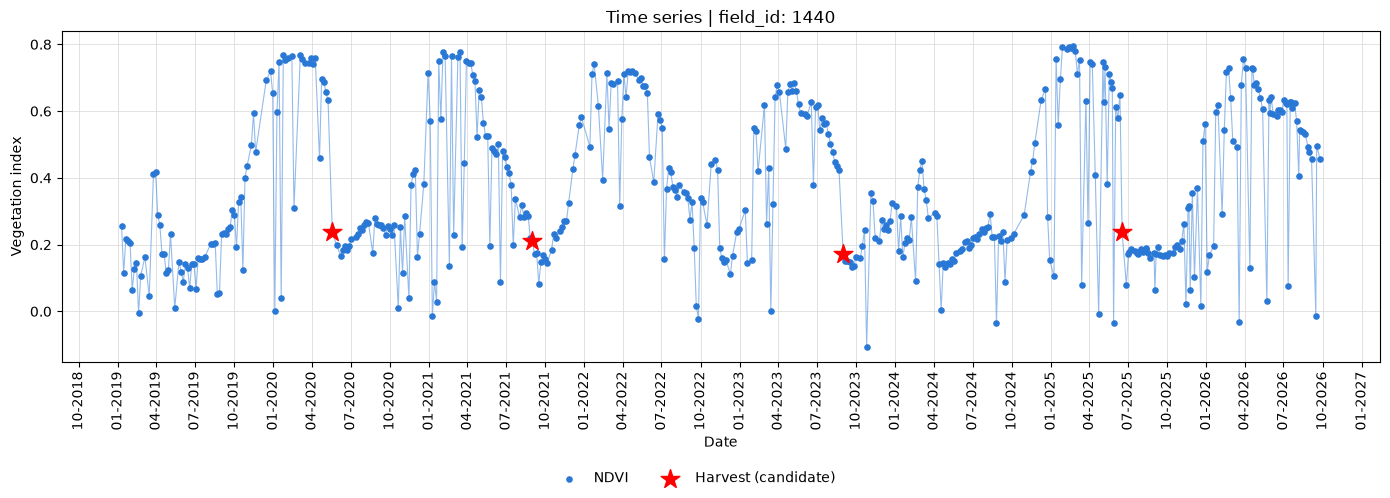

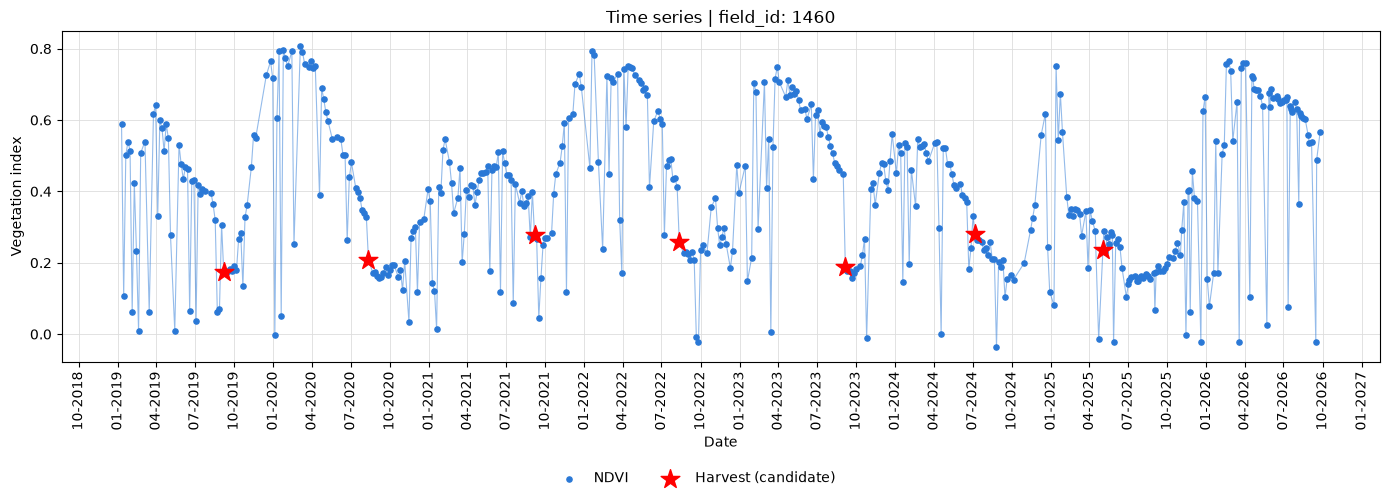

In [7]:
for field_id in FIELDS_TO_PLOT:
    save_path = None
    if SAVE_FIGURES:
        file_name = f"timeseries_{field_id}_{'_'.join(INDICES_TO_PLOT)}.png"
        save_path = FIGURES_DIR / file_name
    plot_index_timeseries(
        df,
        INDICES_TO_PLOT,
        field_id,
        harvests=harvests if SHOW_HARVESTS else None,
        save_path=save_path,
    )
    plt.show()